<a href="https://colab.research.google.com/github/zack11112022/Tugas-probabilitas-stastika-Zakaria-Hutabarat/blob/main/Probabilitas_dan_Statistika_Zakaria_Hutabarat.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import re
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
from google.colab import files

In [2]:
up = files.upload()
nama_file = list(up.keys())[0]
print("File terbaca:", nama_file)

Saving Blank Quiz (Responses) .xlsx to Blank Quiz (Responses) .xlsx
File terbaca: Blank Quiz (Responses) .xlsx


In [3]:
KELAS = "3 TI A"            # isi None untuk memakai semua kelas (uji coba)
JUMLAH_KOLOM_DEMOGRAFI = 6  # Timestamp, Score, Kelas, JK, Jml platform, Jml premium

df = pd.read_excel(nama_file)
df.columns = [str(c).strip() for c in df.columns]
df = df.dropna(axis=1, how="all")
if KELAS:
    df = df[df["Kelas"].astype(str).str.strip().str.upper() == KELAS.upper()]

# hanya kolom berformat "Dimensi [pernyataan]" (kolom Durasi tidak ikut)
kolom_butir = [c for c in df.columns[JUMLAH_KOLOM_DEMOGRAFI:] if re.match(r"^.*? \[.*\]$", c)]
butir = df[kolom_butir]

print("Jumlah responden :", len(df))
print("Jumlah butir     :", butir.shape[1])
print("Data kosong      :", int(butir.isna().sum().sum()))

Jumlah responden : 39
Jumlah butir     : 29
Data kosong      : 0


In [4]:
skala = {
    "Sangat Tidak Setuju (STS)": 1,
    "Tidak Setuju (TS)": 2,
    "Netral (N)": 3,
    "Setuju (S)": 4,
    "Sangat Setuju (SS)": 5,
}
num = butir.apply(lambda s: s.astype(str).str.strip().map(skala)).astype(float)

print("Sel yang gagal dikonversi:", int(num.isna().sum().sum()))  # harus 0
num.head()

Sel yang gagal dikonversi: 0


,Penggunaan AI pada tugas atau projek kuliah [Saya menggunakan platform AI hampir setiap kali mendapatkan tugas akademik.],Penggunaan AI pada tugas atau projek kuliah [Saya menggunakan AI untuk mencari solusi atas permasalahan atau soal perkuliahan.],Penggunaan AI pada tugas atau projek kuliah [Saya menggunakan AI untuk mencari ide atau inspirasi dalam mengerjakan tugas./projek],Penggunaan AI pada tugas atau projek kuliah [Saya merasa kesulitan memulai mengerjakan tugas tanpa bantuan AI.],Penggunaan AI pada tugas atau projek kuliah [Saya merasa kurang yakin dengan hasil tugas apabila tidak menggunakan AI.],Penggunaan AI pada tugas atau projek kuliah [Saya percaya bahwa AI dapat memberikan informasi yang membantu penyelesaian tugas.],Penggunaan AI pada tugas atau projek kuliah [Saya memeriksa kembali kebenaran informasi yang diberikan AI sebelum menggunakannya.],Aspek Psikologis penggunaan AI pada tugas atau projek kuliah [Saya merasa perlu menggunakan AI setiap kali mendapatkan tugas atau proyek kuliah.],Aspek Psikologis penggunaan AI pada tugas atau projek kuliah [aya merasa kesulitan menyelesaikan tugas kuliah apabila tidak menggunakan bantuan AI.],Aspek Psikologis penggunaan AI pada tugas atau projek kuliah [Saya cenderung mengikuti saran atau jawaban AI tanpa banyak mempertimbangkan alternatif lainnya (Non-AI).],...,Kebiasaan penggunaan teknologi digital [Saya jarang memeriksa kembali hasil dari AI karena sudah percaya terhadap ketepatan jawabannya.],Prokrastinasi akademik. [Saya cenderung menunggu hingga mendekati deadline untuk mulai mengerjakan tugas.],Prokrastinasi akademik. [Saya sering menunda pengerjaan tugas karena merasa dapat dikerjakan dengan mudah dan cepat dengan menggunakan AI],Prokrastinasi akademik. [Saya sering menyelesaikan tugas kuliah dalam waktu yang sangat dekat dengan batas pengumpulan.],Prokrastinasi akademik. [Saya sering mengerjakan beberapa tugas sekaligus karena sebelumnya menunda pengerjaannya.],Rsspon emosional [Saya merasa tertekan ketika harus menyelesaikan tugas dalam waktu singkat akibat menunda pengerjaannya.],Rsspon emosional [Saya merasa panik ketika beberapa tugas yang saya tunda memiliki batas waktu pengumpulan yang berdekatan.],Rsspon emosional [Saya merasa kurang puas terhadap hasil tugas yang dikerjakan karena terburu-buru mendekati deadline.],Rsspon emosional [Saya merasa lega setelah berhasil mengumpulkan tugas meskipun pengerjaannya dilakukan AI saat mendekati deadline.],Rsspon emosional [Saya merasa menyesal karena hasil tugas mungkin bisa lebih baik apabila dikerjakan lebih awal.]
142,3.0,4.0,5.0,3.0,4.0,5.0,5.0,4.0,3.0,3.0,...,2.0,3.0,3.0,3.0,3.0,4.0,4.0,5.0,4.0,5.0
143,4.0,5.0,4.0,4.0,2.0,5.0,4.0,3.0,4.0,2.0,...,3.0,4.0,2.0,3.0,4.0,1.0,2.0,3.0,4.0,5.0
144,4.0,4.0,4.0,4.0,2.0,4.0,5.0,4.0,3.0,2.0,...,1.0,4.0,5.0,4.0,5.0,4.0,3.0,4.0,5.0,5.0
145,5.0,4.0,2.0,1.0,1.0,5.0,5.0,1.0,2.0,3.0,...,1.0,5.0,4.0,4.0,5.0,5.0,1.0,5.0,3.0,1.0
146,4.0,4.0,5.0,3.0,4.0,5.0,4.0,5.0,4.0,3.0,...,2.0,1.0,1.0,1.0,1.0,4.0,4.0,5.0,1.0,5.0


In [5]:
KOREKSI = {"Rsspon emosional": "Respon emosional",
           "Prokrastinasi akademik.": "Prokrastinasi akademik"}

dimensi = {}
for kolom in butir.columns:
    nama = re.match(r"^(.*?) \[", kolom).group(1).strip()
    nama = KOREKSI.get(nama, nama)
    dimensi.setdefault(nama, []).append(kolom)

for nama, daftar in dimensi.items():
    print(f"{nama}: {len(daftar)} butir")

Penggunaan AI pada tugas atau projek kuliah: 7 butir
Aspek Psikologis penggunaan AI pada tugas atau projek kuliah: 7 butir
Kebiasaan penggunaan teknologi digital: 6 butir
Prokrastinasi akademik: 4 butir
Respon emosional: 5 butir


In [6]:
n = len(num)
t = stats.t.ppf(0.975, n - 2)
r_tabel = t / np.sqrt((n - 2) + t**2)
print(f"n = {n} | r tabel (α=0,05; df={n-2}) = {r_tabel:.3f}")

hasil_validitas = []
for nama, daftar in dimensi.items():
    x = num[daftar]
    total = x.sum(axis=1)
    for i, kolom in enumerate(daftar, 1):
        r, p = stats.pearsonr(x[kolom], total)
        r_koreksi, _ = stats.pearsonr(x[kolom], total - x[kolom])
        hasil_validitas.append({
            "Dimensi": nama,
            "Butir": f"B{i}",
            "r hitung": round(r, 3),
            "Corrected r": round(r_koreksi, 3),
            "p-value": round(p, 4),
            "Keterangan": "Valid" if r > r_tabel else "Tidak valid",
        })

tabel_validitas = pd.DataFrame(hasil_validitas)
tabel_validitas

n = 39 | r tabel (α=0,05; df=37) = 0.316


,Dimensi,Butir,r hitung,Corrected r,p-value,Keterangan
0,Penggunaan AI pada tugas atau projek kuliah,B1,0.525,0.277,0.0006,Valid
1,Penggunaan AI pada tugas atau projek kuliah,B2,0.269,0.105,0.0972,Tidak valid
2,Penggunaan AI pada tugas atau projek kuliah,B3,0.643,0.379,0.0000,Valid
3,Penggunaan AI pada tugas atau projek kuliah,B4,0.669,0.397,0.0000,Valid
4,Penggunaan AI pada tugas atau projek kuliah,B5,0.515,0.126,0.0008,Valid
5,Penggunaan AI pada tugas atau projek kuliah,B6,0.455,0.139,0.0036,Valid
6,Penggunaan AI pada tugas atau projek kuliah,B7,0.016,-0.247,0.9237,Tidak valid
7,Aspek Psikologis penggunaan AI pada tugas atau...,B1,0.538,0.228,0.0004,Valid
8,Aspek Psikologis penggunaan AI pada tugas atau...,B2,0.645,0.377,0.0000,Valid
9,Aspek Psikologis penggunaan AI pada tugas atau...,B3,0.495,0.213,0.0014,Valid


In [7]:
def cronbach_alpha(x):
    k = x.shape[1]
    return k / (k - 1) * (1 - x.var(ddof=1).sum() / x.sum(axis=1).var(ddof=1))

def kategori(a):
    return ("Sangat baik" if a >= 0.90 else "Baik" if a >= 0.80
            else "Reliabel" if a >= 0.70 else "Tidak reliabel")

hasil_reliabilitas = []
alpha_dihapus = []

for nama, daftar in dimensi.items():
    x = num[daftar]
    a = cronbach_alpha(x)
    hasil_reliabilitas.append({
        "Dimensi": nama,
        "Jumlah butir": len(daftar),
        "Cronbach's alpha": round(a, 3),
        "Kategori": kategori(a),
    })
    for i, kolom in enumerate(daftar, 1):
        if len(daftar) > 2:
            alpha_dihapus.append({
                "Dimensi": nama,
                "Butir": f"B{i}",
                "Alpha jika dihapus": round(cronbach_alpha(x.drop(columns=kolom)), 3),
            })

tabel_reliabilitas = pd.DataFrame(hasil_reliabilitas)
tabel_alpha_dihapus = pd.DataFrame(alpha_dihapus)
display(tabel_reliabilitas)
display(tabel_alpha_dihapus)

,Dimensi,Jumlah butir,Cronbach's alpha,Kategori
0,Penggunaan AI pada tugas atau projek kuliah,7,0.370,Tidak reliabel
1,Aspek Psikologis penggunaan AI pada tugas atau...,7,0.375,Tidak reliabel
2,Kebiasaan penggunaan teknologi digital,6,0.478,Tidak reliabel
3,Prokrastinasi akademik,4,0.863,Baik
4,Respon emosional,5,0.489,Tidak reliabel


,Dimensi,Butir,Alpha jika dihapus
0,Penggunaan AI pada tugas atau projek kuliah,B1,0.275
1,Penggunaan AI pada tugas atau projek kuliah,B2,0.362
2,Penggunaan AI pada tugas atau projek kuliah,B3,0.193
3,Penggunaan AI pada tugas atau projek kuliah,B4,0.171
4,Penggunaan AI pada tugas atau projek kuliah,B5,0.367
5,Penggunaan AI pada tugas atau projek kuliah,B6,0.348
6,Penggunaan AI pada tugas atau projek kuliah,B7,0.513
7,Aspek Psikologis penggunaan AI pada tugas atau...,B1,0.299
8,Aspek Psikologis penggunaan AI pada tugas atau...,B2,0.200
9,Aspek Psikologis penggunaan AI pada tugas atau...,B3,0.312


In [8]:
gabung = tabel_validitas.merge(tabel_alpha_dihapus, on=["Dimensi", "Butir"], how="left")
alpha_dim = tabel_reliabilitas.set_index("Dimensi")["Cronbach's alpha"]

def keputusan(b):
    valid = b["Keterangan"] == "Valid"
    naik = b["Alpha jika dihapus"] > alpha_dim[b["Dimensi"]]
    if valid and not naik: return "Pertahankan"
    if valid and naik:     return "Tinjau isi butir (ambigu/beda konstruk)"
    if not valid and naik: return "Buang atau revisi, lalu uji ulang"
    return "Tinjau ulang sebelum dibuang"

gabung["Keputusan"] = gabung.apply(keputusan, axis=1)

with pd.ExcelWriter("hasil_uji_validitas_reliabilitas.xlsx") as w:
    gabung.to_excel(w, sheet_name="Validitas", index=False)
    tabel_reliabilitas.to_excel(w, sheet_name="Reliabilitas", index=False)

files.download("hasil_uji_validitas_reliabilitas.xlsx")
gabung[["Dimensi", "Butir", "r hitung", "Alpha jika dihapus", "Keterangan", "Keputusan"]]

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

,Dimensi,Butir,r hitung,Alpha jika dihapus,Keterangan,Keputusan
0,Penggunaan AI pada tugas atau projek kuliah,B1,0.525,0.275,Valid,Pertahankan
1,Penggunaan AI pada tugas atau projek kuliah,B2,0.269,0.362,Tidak valid,Tinjau ulang sebelum dibuang
2,Penggunaan AI pada tugas atau projek kuliah,B3,0.643,0.193,Valid,Pertahankan
3,Penggunaan AI pada tugas atau projek kuliah,B4,0.669,0.171,Valid,Pertahankan
4,Penggunaan AI pada tugas atau projek kuliah,B5,0.515,0.367,Valid,Pertahankan
5,Penggunaan AI pada tugas atau projek kuliah,B6,0.455,0.348,Valid,Pertahankan
6,Penggunaan AI pada tugas atau projek kuliah,B7,0.016,0.513,Tidak valid,"Buang atau revisi, lalu uji ulang"
7,Aspek Psikologis penggunaan AI pada tugas atau...,B1,0.538,0.299,Valid,Pertahankan
8,Aspek Psikologis penggunaan AI pada tugas atau...,B2,0.645,0.200,Valid,Pertahankan
9,Aspek Psikologis penggunaan AI pada tugas atau...,B3,0.495,0.312,Valid,Pertahankan


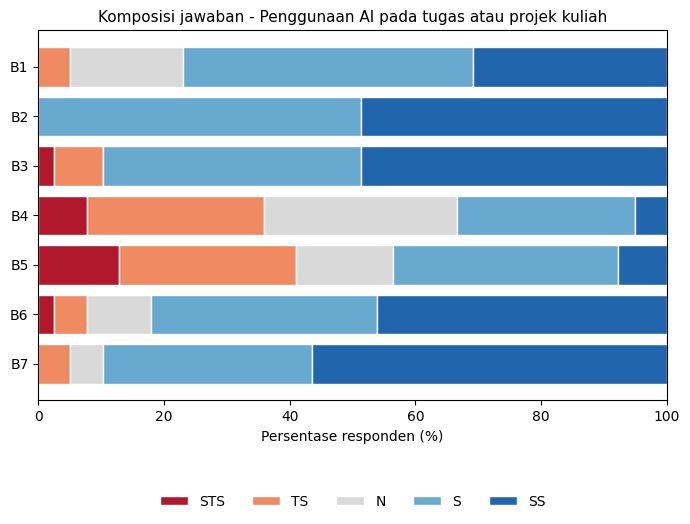

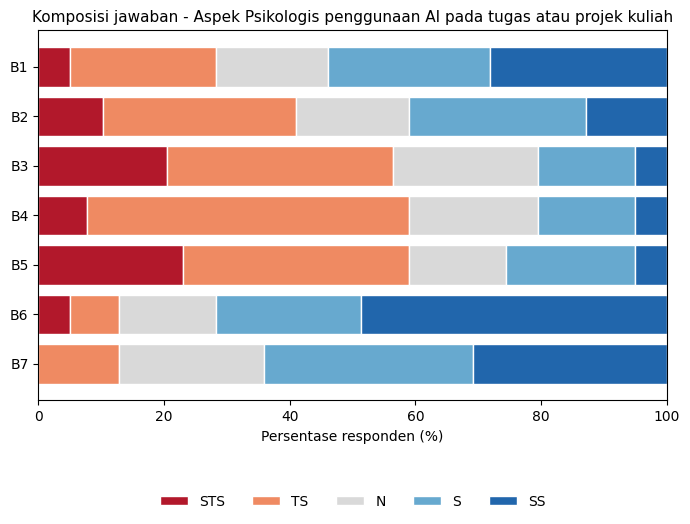

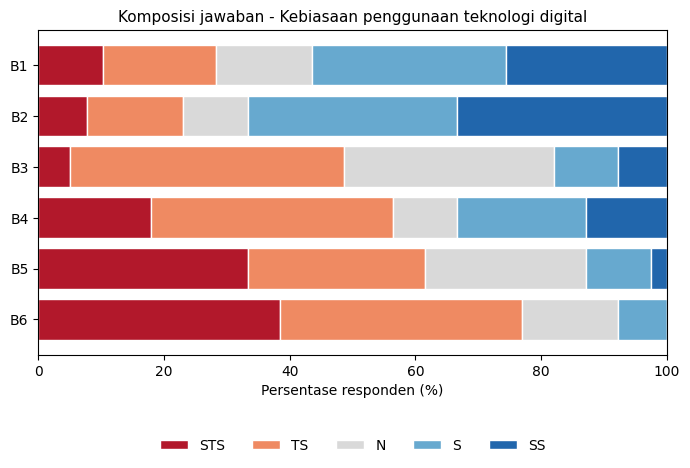

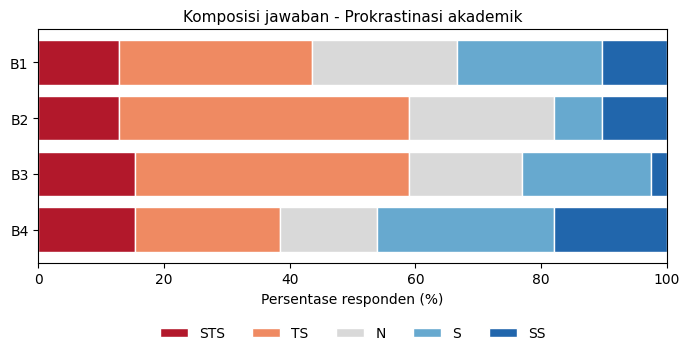

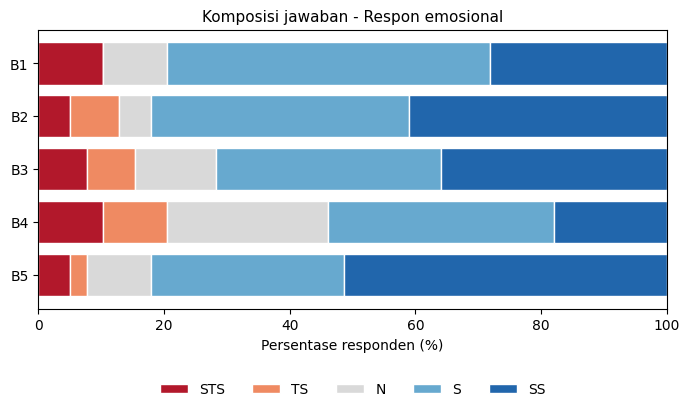

,Dimensi,Mean total,SD,Skewness,Kurtosis
0,Penggunaan AI pada tugas atau projek kuliah,27.28,3.017,-0.425,1.612
1,Aspek Psikologis penggunaan AI pada tugas atau...,21.92,3.737,0.248,-0.752
2,Kebiasaan penggunaan teknologi digital,16.69,3.722,-0.255,-0.212
3,Prokrastinasi akademik,11.05,4.065,0.236,-0.553
4,Respon emosional,19.38,3.322,-1.524,3.948


In [9]:
label = {1: "STS", 2: "TS", 3: "N", 4: "S", 5: "SS"}
warna = ["#b2182b", "#ef8a62", "#d9d9d9", "#67a9cf", "#2166ac"]
deskriptif = []

for nama, daftar in dimensi.items():
    kodes = [f"B{i}" for i in range(1, len(daftar) + 1)]
    pct = pd.DataFrame({k: num[c].value_counts(normalize=True).reindex([1,2,3,4,5]).fillna(0) * 100
                        for k, c in zip(kodes, daftar)}).T
    fig, ax = plt.subplots(figsize=(7, 0.55 * len(kodes) + 1.6))
    left = np.zeros(len(kodes))
    for v, w in zip([1,2,3,4,5], warna):
        ax.barh(kodes, pct[v], left=left, color=w, label=label[v], edgecolor="white")
        left += pct[v].values
    ax.invert_yaxis(); ax.set_xlim(0, 100); ax.set_xlabel("Persentase responden (%)")
    ax.set_title(f"Komposisi jawaban - {nama}", fontsize=11)
    ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.22), frameon=False)
    fig.tight_layout()
    nama_file_gambar = "komposisi_" + re.sub(r"\W+", "_", nama) + ".png"
    fig.savefig(nama_file_gambar, dpi=200)
    plt.show()

    tot = num[daftar].sum(axis=1)
    deskriptif.append({"Dimensi": nama, "Mean total": round(tot.mean(), 2),
                       "SD": round(tot.std(ddof=1), 3),
                       "Skewness": round(stats.skew(tot, bias=False), 3),
                       "Kurtosis": round(stats.kurtosis(tot, bias=False), 3)})

pd.DataFrame(deskriptif)

In [10]:
# Latihan 2: perbandingan kriteria
print("Valid (r hitung > r tabel)  :", (tabel_validitas["r hitung"] > r_tabel).sum(), "dari", len(tabel_validitas))
print("Valid (corrected r >= 0,30) :", (tabel_validitas["Corrected r"] >= 0.30).sum(), "dari", len(tabel_validitas))

# Latihan 3: buang satu butir, bandingkan alpha (ubah dua baris ini)
dimensi_uji = list(dimensi.keys())[0]
butir_dibuang = dimensi[dimensi_uji][0]
sebelum = cronbach_alpha(num[dimensi[dimensi_uji]])
sesudah = cronbach_alpha(num[dimensi[dimensi_uji]].drop(columns=butir_dibuang))
print(f"{dimensi_uji}: α sebelum = {sebelum:.3f} | sesudah = {sesudah:.3f}")

# Latihan 4: pengaruh ukuran sampel
m = min(20, len(num))
sub = num.sample(m, random_state=1)
t2 = stats.t.ppf(0.975, m - 2)
r_tabel2 = t2 / np.sqrt((m - 2) + t2**2)
jumlah_valid = 0
for nama, daftar in dimensi.items():
    x = sub[daftar]; total = x.sum(axis=1)
    for kolom in daftar:
        r, _ = stats.pearsonr(x[kolom], total)
        jumlah_valid += int(r > r_tabel2)
print(f"n = {m} | r tabel = {r_tabel2:.3f} | butir valid = {jumlah_valid} dari {num.shape[1]}")

Valid (r hitung > r tabel)  : 24 dari 29
Valid (corrected r >= 0,30) : 13 dari 29
Penggunaan AI pada tugas atau projek kuliah: α sebelum = 0.370 | sesudah = 0.275
n = 20 | r tabel = 0.444 | butir valid = 23 dari 29
